# 02 · Exploratory data analysis

Each finding is followed by **why it matters** for model choice. Everything is regenerated by `src/analysis/eda.py` (run in the next cell), so the figures and numbers below come from code executed in this notebook.

In [1]:
import os, sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
def show(fig): display(Image(filename=f"reports/figures/{fig}"))
def J(path): return json.load(open(path))

In [2]:
import contextlib, io
from src.analysis import eda
with contextlib.redirect_stdout(io.StringIO()):
    eda.main()
E = J("reports/eda_summary.json")
print("EDA regenerated")

EDA regenerated


## 1. Level, trend, structural change

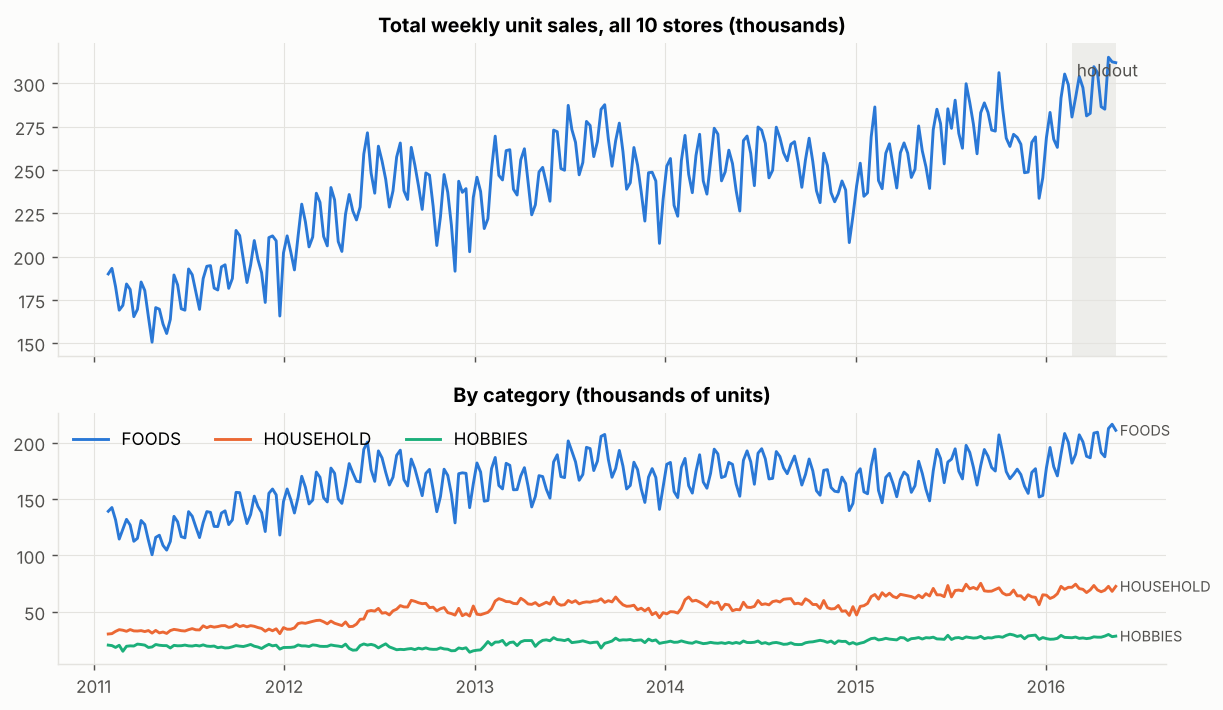

,ds,mean,std,count,cv
0,2011,184182.0,15722.0,49,0.0
1,2012,231149.0,19463.0,52,0.0
2,2013,252017.0,18394.0,52,0.0
3,2014,251163.0,15742.0,52,0.0
4,2015,264757.0,17574.0,52,0.0
5,2016,292195.0,15780.0,20,0.0


In [3]:
show("01_total_and_categories.png")
display(pd.read_csv("reports/tables/total_by_year.csv").round(0))

**Observed:** the average weekly total grows from about 184k units (2011) to 231k (2012) and 252k (2013), plateaus in 2014 (251k), then rises to 265k (2015) and 283k in early 2016 (pre-holdout weeks; the yearly table includes the holdout). FOODS is about 70% of units. The 2011-2012 rise is steep and not repeated.
**Why it matters:** there is a real **trend with changing slope**. Models that cannot follow the level (seasonal naive repeats last year's level exactly) will under-forecast in growth years. Differencing (d = 1) or a trend component is needed.

## 2. STL decomposition and outliers

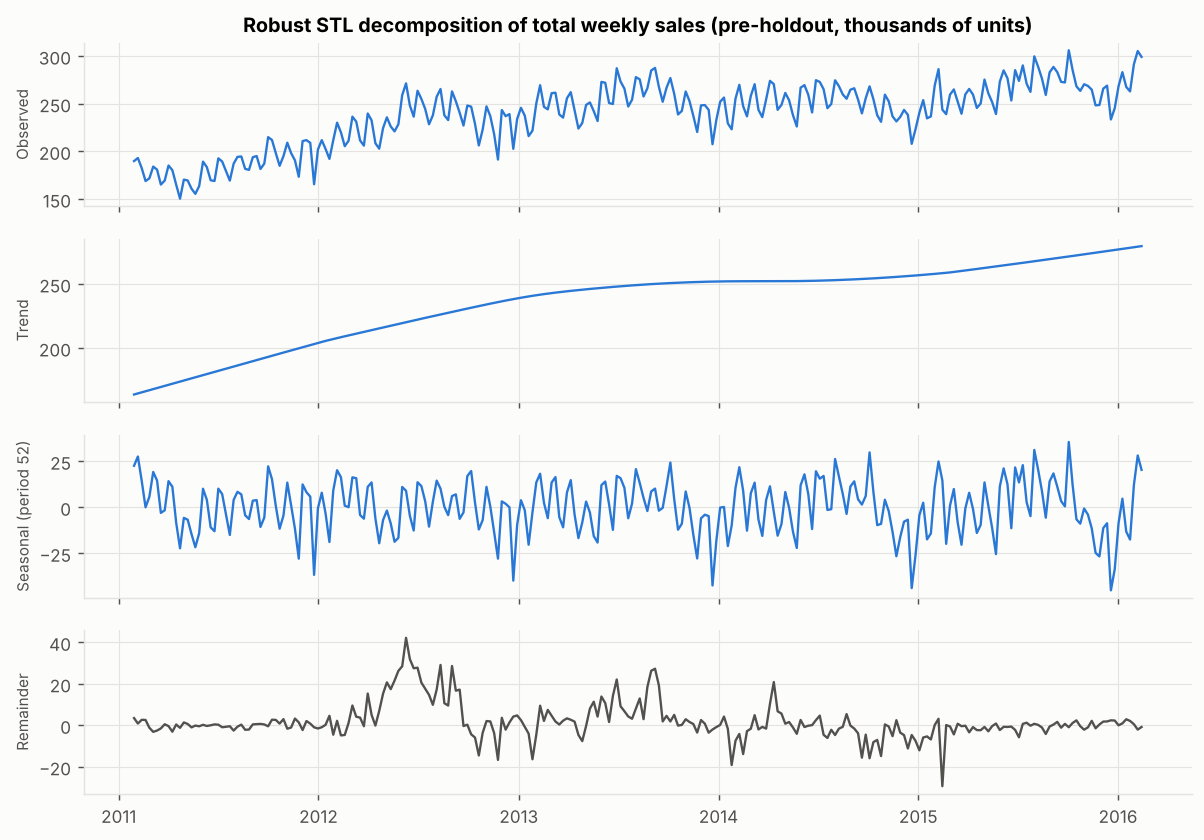

38 weeks with |robust z| > 3.5 on the STL remainder; 21 of them in 2012


,week_start,total_units,stl_remainder,robust_z,events_in_week
0,2012-03-31,239869.0,15372.0,4.26,NaN
1,2012-04-28,224547.0,15308.0,4.24,NaN
2,2012-05-05,235822.0,20767.0,5.79,NaN
3,2012-05-12,226293.0,17498.0,4.86,NaN
4,2012-05-19,221133.0,21627.0,6.04,NaN
5,2012-05-26,228607.0,26305.0,7.37,NaN
6,2012-06-02,259176.0,28535.0,8.00,NaN
7,2012-06-09,271473.0,42236.0,11.89,NaN
8,2012-06-16,248253.0,31944.0,8.97,NaN
9,2012-06-23,236584.0,27562.0,7.72,NaN


In [4]:
show("02_stl_total.png")
o = pd.read_csv("reports/tables/outliers_total.csv")
print(len(o), "weeks with |robust z| > 3.5 on the STL remainder;", (pd.to_datetime(o.week_start).dt.year == 2012).sum(), "of them in 2012")
display(o.head(12))

**Why STL rather than classical decomposition?** STL (LOESS-based) lets the seasonal shape evolve over time and, with `robust=True`, down-weights outliers so they don't distort the trend or seasonal estimates. Classical decomposition assumes a fixed seasonal pattern and loses half a period at each end.

**Observed:** the "outliers" are not isolated spikes. They come in long runs (for example May to September 2012 are all positive). That is the signature of a **level shift / changing seasonal amplitude** that the deliberately smooth STL trend (about 100-week window) does not follow, not of bad data.

**Decision:** **leave** them. Capping would erase a real demand change; deleting would create gaps. Models with a stochastic level (ARIMA with d = 1, ETS) adapt to such shifts; this is noted as a threat to fixed-pattern models.

## 3. Calendar effects: day of week, month, week of year, events, SNAP, price

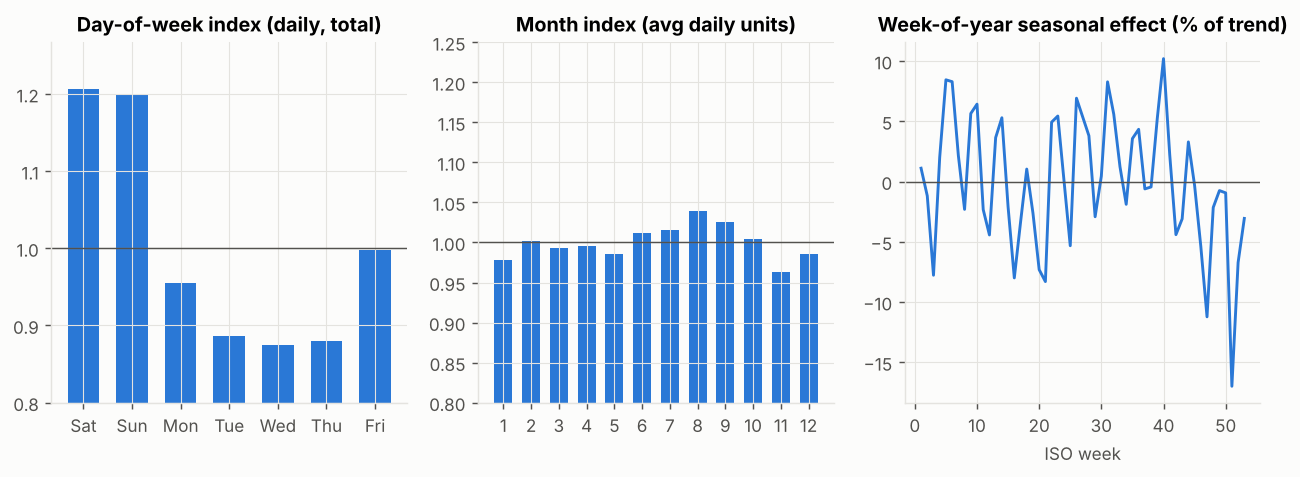

,event,n_weeks,mean_lift_vs_adjacent_weeks_pct
0,christmas,5,-13.15
1,thanksgiving,5,-2.03
2,easter,6,-2.00
3,superbowl,6,3.68
4,other_events,110,0.66


,state,foods_daily_nonSNAP,foods_daily_SNAP,lift_pct
0,CA,9773.51,10733.38,9.82
1,TX,6478.53,7462.33,15.19
2,WI,6220.04,8051.98,29.45


price effect on SKU sample: {'n_price_changes': 434, 'share_sku_weeks_with_price_change': 0.014, 'median_abs_price_change_pct': 10.61, 'corr_dlogprice_dlogunits': -0.033, 'ols_slope_dlogunits_on_dlogprice': -0.143}


In [5]:
show("03_calendar_effects.png")
display(pd.DataFrame(E["event_effects"]))
display(pd.DataFrame(E["snap_effect"]).round(2))
print("price effect on SKU sample:", {k: round(v, 3) for k, v in E["price_effect"].items()})

**Observed and why it matters**
- **Day of week:** Saturday and Sunday are about 20% above the average day and Tuesday to Thursday about 12% below. Weekly buckets absorb this completely, which is a big reason to model weekly.
- **Month / week of year:** a modest annual pattern (August is about 4% above average, November about 4% below) and a sharp **Christmas-week dip (-13% vs adjacent weeks)** because stores close on 25 December. Thanksgiving and Easter weeks are about -2%; Super Bowl week is about +4%. So seasonality is **real but moderate** (seasonal strength 0.75 on the total, notebook 03).
- **SNAP:** FOODS sell 10% (CA), 15% (TX) and **29% (WI)** more on SNAP days. SNAP days fall in the first half of each month, which creates a **~4.3-week cycle in weekly data** that a 52-week seasonal model cannot represent. Known-in-advance SNAP regressors (DHR-ARIMAX, Prophet, LightGBM) can.
- **Price:** only 1.4% of SKU-weeks have a price change (median size 10.6%); the log-units vs log-price correlation is -0.03. Price is a **weak driver here**, and there are no promotion flags (a limitation).

## 4. Autocorrelation and differencing (TOTAL)

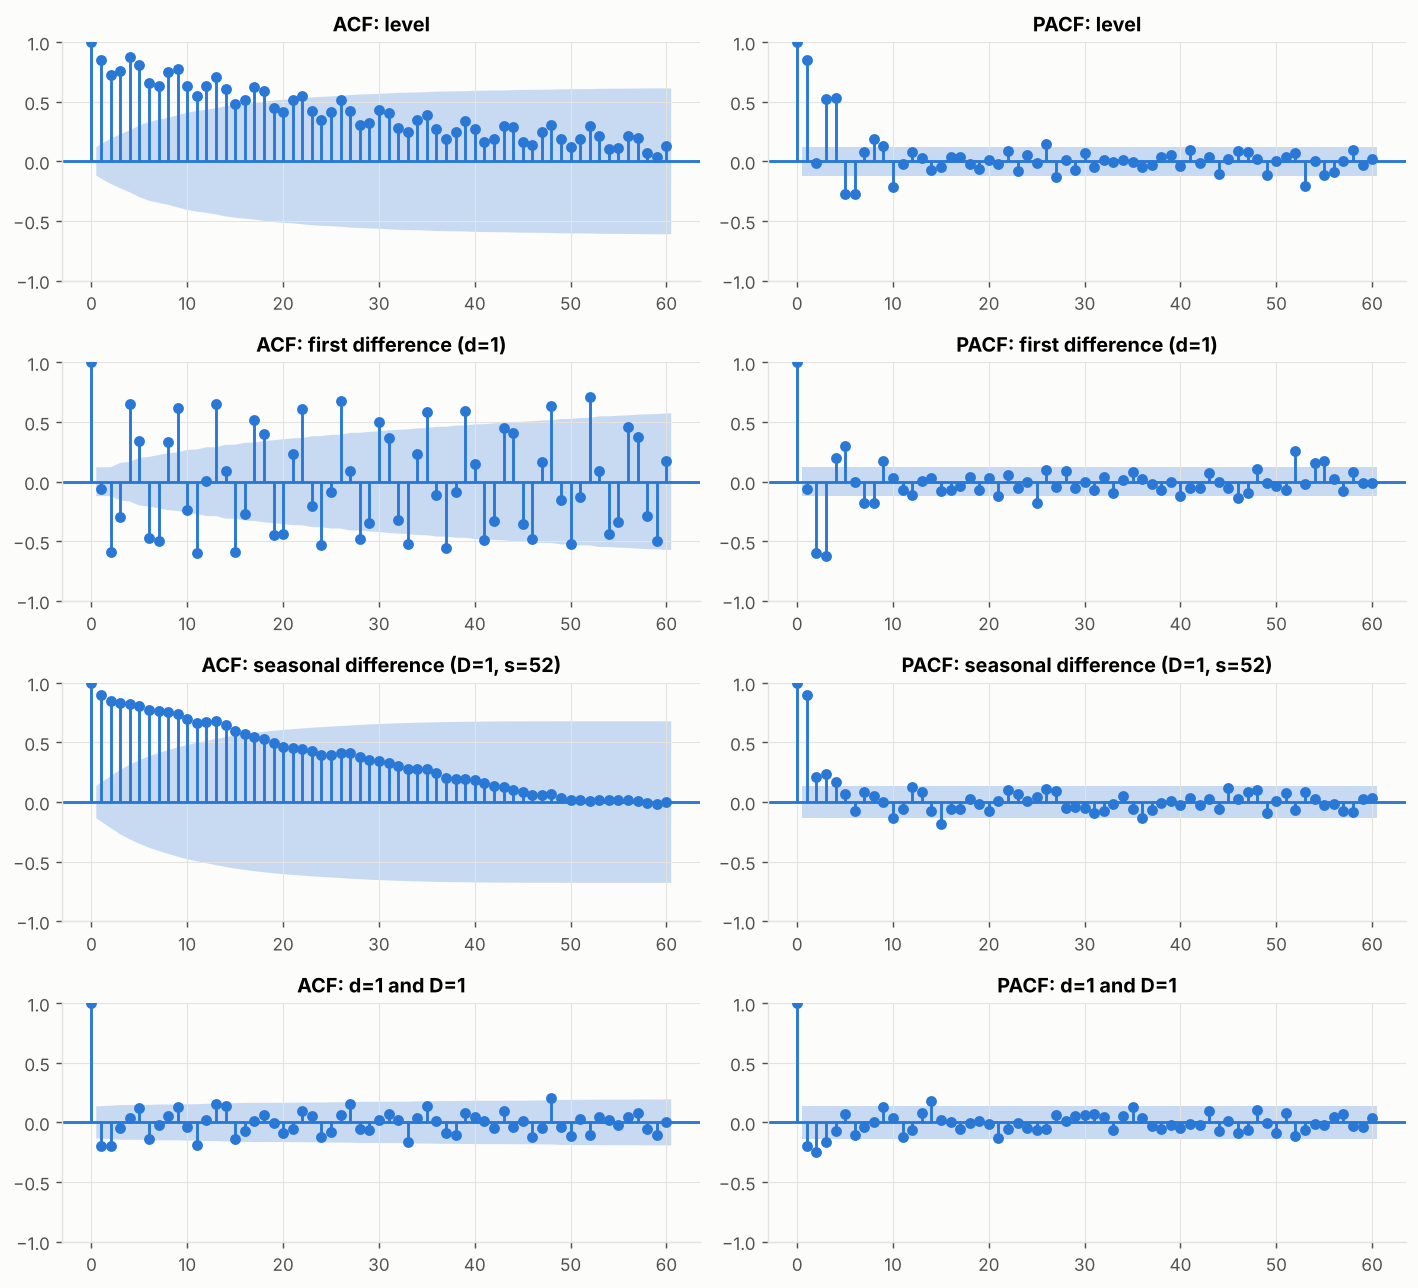

,level,first difference (d=1),"seasonal difference (D=1, s=52)",d=1 and D=1
1,0.85,-0.07,0.90,-0.20
2,0.72,-0.59,0.85,-0.20
4,0.87,0.65,0.83,0.04
13,0.71,0.66,0.68,0.16
26,0.51,0.67,0.41,0.06
51,0.19,-0.13,0.01,0.03
52,0.30,0.71,0.01,-0.10
53,0.21,0.09,0.02,0.04


In [6]:
show("04_acf_pacf_total.png")
display(pd.DataFrame(E["acf_total"]).round(2))

**Reading the ACF/PACF in words**
- *Level:* the ACF decays slowly (0.85 at lag 1, still 0.71 at lag 13), which is the textbook sign of a **unit root / trend**. Differencing is needed (d = 1).
- *After d = 1:* the lag-1 ACF is about -0.07, but **lag 2 = -0.59, lag 4 = +0.65, lag 13 = +0.66, lag 26 = +0.67 and lag 52 = +0.71**. The alternating lag-2/lag-4 pattern is the ~4-week (SNAP/payday) cycle; the large lag-52 spike is the annual cycle. Both remain, so differencing alone is not enough.
- *After D = 1 (s = 52):* lag-52 ACF ≈ 0.01, so seasonal differencing removes the annual pattern, but lag-1 ACF = 0.90 shows a remaining trend, so d = 1 is also needed.
- *After d = 1 and D = 1:* small negative spikes at lag 1 (-0.20) and lag 52 (-0.10). Small negative lag-1/lag-s autocorrelations after differencing are the classic signature of an **MA(1) x seasonal MA(1)** ("airline") structure, and a hint that we might be close to over-differencing (strong negative lag-1 would be the alarm sign; -0.20 is mild).

## 5. Stationarity tests (21 aggregate series)

In [7]:
st = pd.read_csv("reports/tables/stationarity_tests.csv")
display(st.groupby(["transform", "verdict"]).size().unstack(fill_value=0))
display(st[st.unique_id == "TOTAL"].round(4))

verdict,"conflict: ADF rejects unit root, KPSS rejects stationarity (trend/difference-stationary?)",conflict: neither rejects (low power),non-stationary (both agree),stationary (both agree)
transform,,,,
D=1,2,6,12,1
d=1,0,0,0,21
"d=1,D=1",0,0,0,21
level,2,0,19,0


,unique_id,transform,adf_p,kpss_p,verdict
0,TOTAL,level,0.2915,0.01,non-stationary (both agree)
1,TOTAL,d=1,0.0000,0.10,stationary (both agree)
2,TOTAL,D=1,0.2749,0.01,non-stationary (both agree)
3,TOTAL,"d=1,D=1",0.0050,0.10,stationary (both agree)


**How to read ADF and KPSS together:** ADF's null hypothesis is *"unit root (non-stationary)"*; KPSS's null is *"stationary"*. They are complementary:
both say stationary means stationary; both say non-stationary means difference it; disagreement usually means trend-stationarity, a structural break, or low power.

**Observed:** at level, all 21 aggregates are non-stationary or conflicting. After **d = 1, all 21 are stationary by both tests**. Seasonal differencing alone (D = 1) makes only 1 of 21 stationary.
**Implication for SARIMA:** d = 1 is supported by the tests. The tests cannot decide D (they are not seasonal-unit-root tests), so D is chosen with the **seasonal-strength rule** used by `auto.arima`/statsforecast (F_S > 0.64 means D = 1), see notebook 03.

## 6. Does variance grow with the level? (Box-Cox question)

In [8]:
print(json.dumps(E["boxcox_total"], indent=1))

{
 "yearly_mean": {
  "2011": 184182.0,
  "2012": 231149.0,
  "2013": 252017.0,
  "2014": 251163.0,
  "2015": 264757.0,
  "2016": 282703.0
 },
 "yearly_std": {
  "2011": 15722.0,
  "2012": 19463.0,
  "2013": 18394.0,
  "2014": 15742.0,
  "2015": 17574.0,
  "2016": 16710.0
 },
 "mle_lambda": 2.7419556652295123,
 "median_loglog_slope_std_on_mean_store_dept": 0.7524703043389225
}


**Observed:** on TOTAL the yearly mean rose by 54% (184k to 283k) while the standard deviation stayed between 16k and 19k. Variance does **not** grow with level, so a log/Box-Cox transform is not needed for the total (the MLE λ of 2.7 just reflects the trend, not variance stabilisation). Across store x department series the log(sd)-on-log(mean) slope has median 0.75, so there is partial level-dependence at lower levels.
**Decision:** no transform by default; tested explicitly for SARIMA on TOTAL in notebook 03 (log changes CV MASE from 0.309 to 0.306, i.e. nothing).

## 7. Series characterisation: the backbone of the 'why' analysis

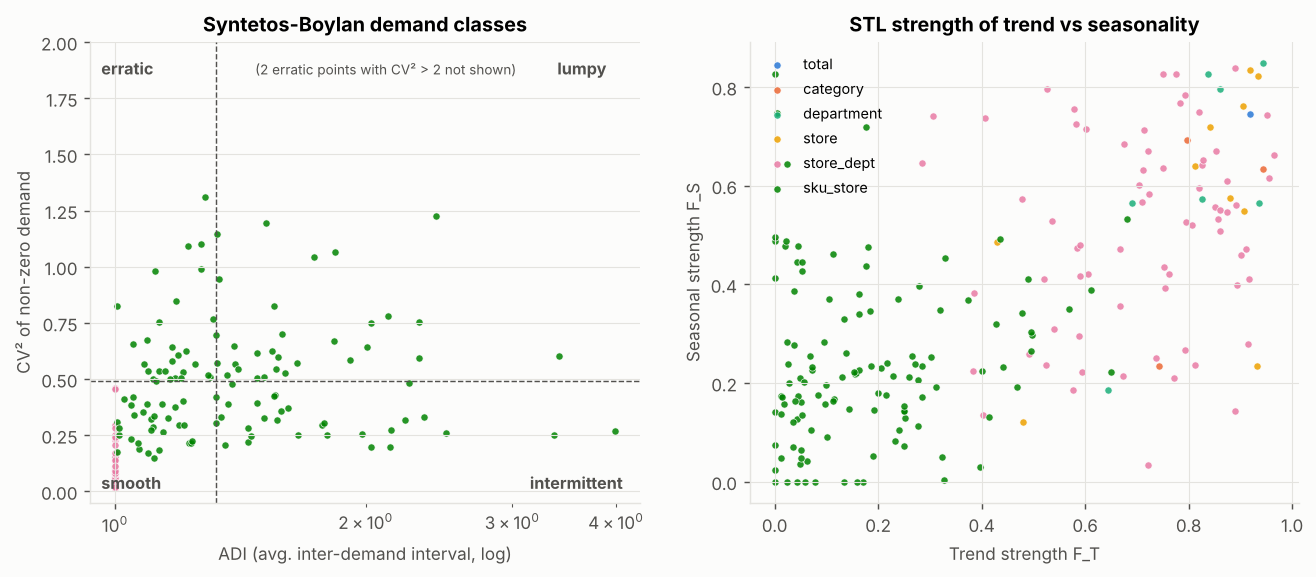

,trend_strength,seasonal_strength,share_zeros,cv,adi,cv2
level,,,,,,
category,0.796,0.634,0.00,0.155,1.000,0.024
department,0.838,0.573,0.00,0.188,1.000,0.035
sku_store,0.141,0.214,0.24,1.014,1.316,0.489
store,0.893,0.607,0.00,0.151,1.000,0.023
store_dept,0.744,0.531,0.00,0.226,1.000,0.051
total,0.919,0.746,0.00,0.140,1.000,0.020


sbc_class,erratic,intermittent,lumpy,smooth
level,,,,
category,0,0,0,3
department,0,0,0,7
sku_store,30,30,30,30
store,0,0,0,10
store_dept,0,0,0,70
total,0,0,0,1


In [9]:
ch = pd.read_csv("reports/series_characteristics.csv")
show("05_series_characteristics.png")
display(ch.groupby("level")[["trend_strength", "seasonal_strength", "share_zeros", "cv", "adi", "cv2"]].median().round(3))
display(pd.crosstab(ch.level, ch.sbc_class))

**Definitions**
- *Trend / seasonal strength* (Hyndman): F = max(0, 1 - Var(remainder)/Var(component + remainder)) from the robust STL. 0 means none, 1 means the component explains everything.
- *ADI* = average interval between non-zero weeks; *CV²* = squared coefficient of variation of the non-zero sizes. Syntetos-Boylan cut-offs 1.32 / 0.49 give **smooth, erratic, intermittent, lumpy**.

**Observed:** aggregates are all *smooth* with strong trend (median F_T 0.74-0.92) and moderate-to-strong seasonality (F_S 0.53-0.75). SKUs have weak structure (median F_T 0.14, F_S 0.21), 24% zero weeks and CV about 1.0.
**Why it matters:** this split predicts *before any modelling* that model choice should differ by level. Structure-seeking models (SARIMA/ETS) have something to find in aggregates; at SKU level most of the signal is noise, and the gains over simple methods should be small.

## 8. Zeros, stock-outs and censoring

{'n_sku_with_suspected_stockout_run': 59, 'n_sku': 120, 'by_class': {'erratic': 23, 'intermittent': 10, 'lumpy': 10, 'smooth': 16}}


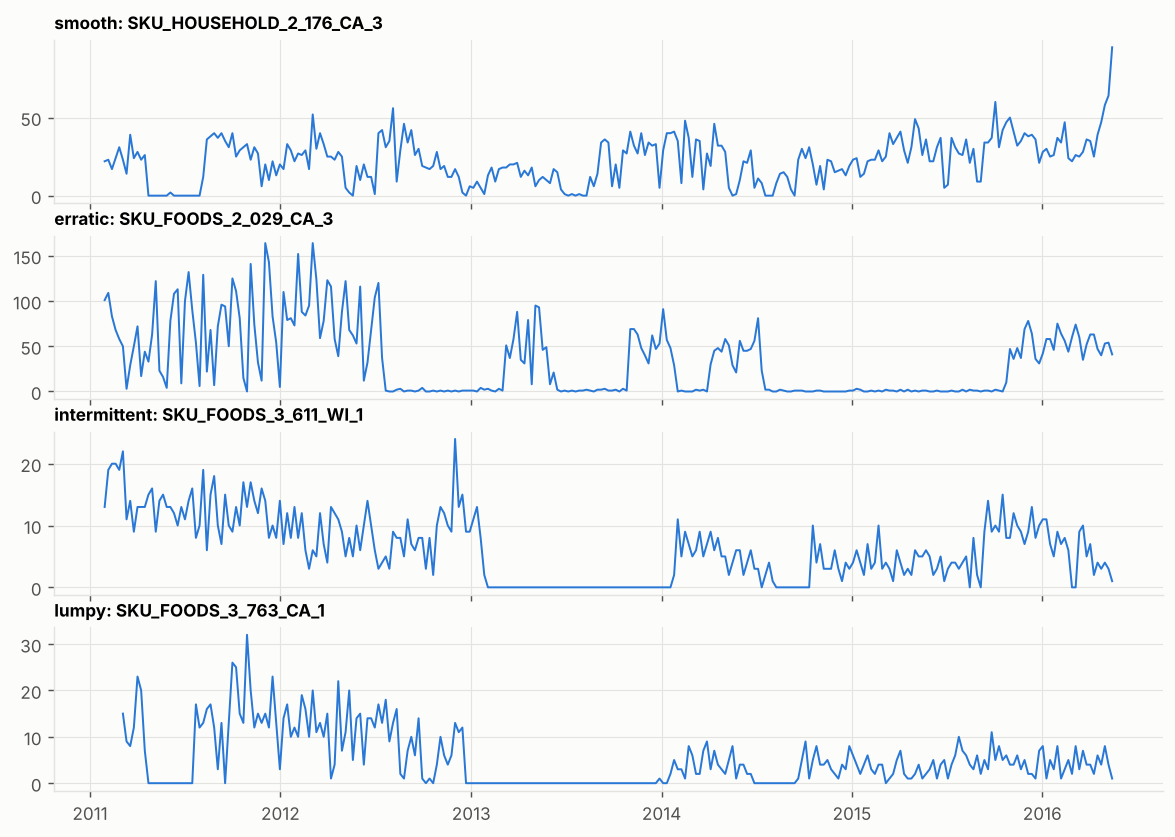

In [10]:
z = pd.read_csv("reports/tables/sku_zero_runs.csv")
print(E["suspected_stockouts"])
show("06_sku_examples.png")

**Observed:** 59 of 120 sampled SKUs have a run of at least 4 consecutive zero weeks despite normally selling at least 5 units in a non-zero week, which is implausible as random zero demand. These are **suspected stock-outs** (or temporary delistings not captured by the price table).
**Decision:** keep them as observed (we cannot know the true demand), but **state the censoring limitation**: models learn *sales*, which understate *demand* during stock-outs; this biases forecasts and safety stocks downward for these items. With real retailer data, one would use inventory/availability records to flag and impute censored weeks.